<a href="https://colab.research.google.com/github/bogdanych/ML-homeworks/blob/pull/practical/%D0%94%D0%971.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [60]:
!pip install --upgrade kagglehub[pandas-datasets] imbalanced-learn -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub
from kagglehub import KaggleDatasetAdapter

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE

sns.set_style("whitegrid")
pd.set_option('display.float_format', lambda x: f'{x:.3f}')
%matplotlib inline

# Шаг 0. Описание задачи
Задача: бинарная классификация. По социально-демографическим и финансовым характеристикам заёмщика (возраст, доход, стаж, сумма кредита, процентная ставка, цель кредита, кредитный рейтинг и т.д.) нужно предсказать, вернёт ли клиент кредит (loan_status = 0) или допустит дефолт (loan_status = 1). Это классическая задача кредитного скоринга. Ошибка в сторону «пропустить дефолт» (False Negative) обычно дороже банку, чем ошибка «отказать хорошему клиенту», поэтому в оценке качества будем ориентироваться не только на Accuracy, но и на Recall и F1 по классу дефолта.

# Шаг 1. Считываем данные

In [61]:
file_path = "credit_risk_dataset.csv"
df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "laotse/credit-risk-dataset",
    file_path
)

print("Размер данных:", df.shape)
display(df.head())
print("\nТипы данных и пропуски:")
df.info()

/tmp/ipykernel_1617/2828722669.py:2: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'credit-risk-dataset' dataset.
Размер данных: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.000,PERSONAL,D,35000,16.020,1,0.590,Y,3
1,21,9600,OWN,5.000,EDUCATION,B,1000,11.140,0,0.100,N,2
2,25,9600,MORTGAGE,1.000,MEDICAL,C,5500,12.870,1,0.570,N,3
3,23,65500,RENT,4.000,MEDICAL,C,35000,15.230,1,0.530,N,2
4,24,54400,RENT,8.000,MEDICAL,C,35000,14.270,1,0.550,Y,4



Типы данных и пропуски:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


#Шаг 2. Разбиение на обучающую и тестовую выборки

In [62]:
X = df.drop('loan_status', axis=1)
y = df['loan_status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y           # важно: сохраняет пропорцию классов
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print("\nДоли классов в train:")
print(y_train.value_counts(normalize=True).round(4))
print("\nДоли классов в test:")
print(y_test.value_counts(normalize=True).round(4))

Train: (26064, 11), Test: (6517, 11)

Доли классов в train:
loan_status
0   0.782
1   0.218
Name: proportion, dtype: float64

Доли классов в test:
loan_status
0   0.782
1   0.218
Name: proportion, dtype: float64


#Шаг 3. Визуализация и основные характеристики

Числовые: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
Категориальные: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

Описательные статистики (train):


,count,mean,std,min,25%,50%,75%,max
person_age,26064.000,27.703,6.327,20.000,23.000,26.000,30.000,144.000
person_income,26064.000,66043.498,63715.995,4000.000,38443.250,55000.000,79000.000,6000000.000
person_emp_length,25326.000,4.795,4.172,0.000,2.000,4.000,7.000,123.000
loan_amnt,26064.000,9569.114,6295.931,500.000,5000.000,8000.000,12000.000,35000.000
loan_int_rate,23563.000,11.016,3.235,5.420,7.900,10.990,13.470,22.480
loan_percent_income,26064.000,0.170,0.107,0.000,0.090,0.150,0.230,0.830
cb_person_cred_hist_length,26064.000,5.787,4.035,2.000,3.000,4.000,8.000,30.000


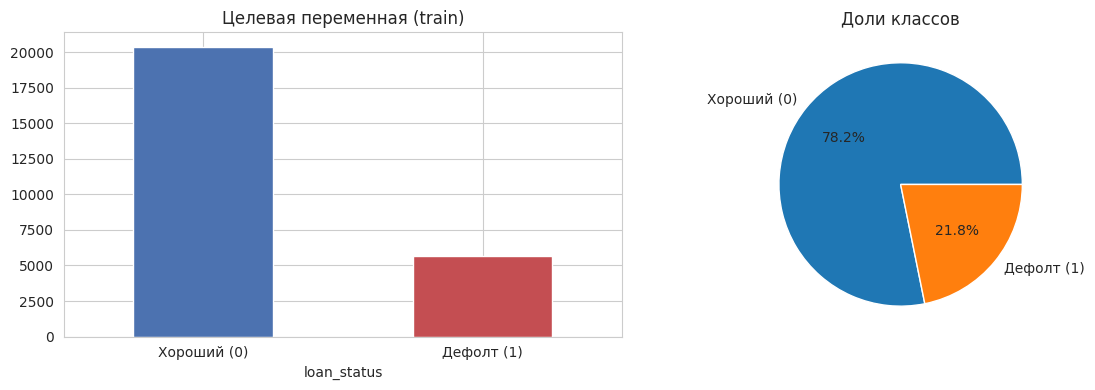

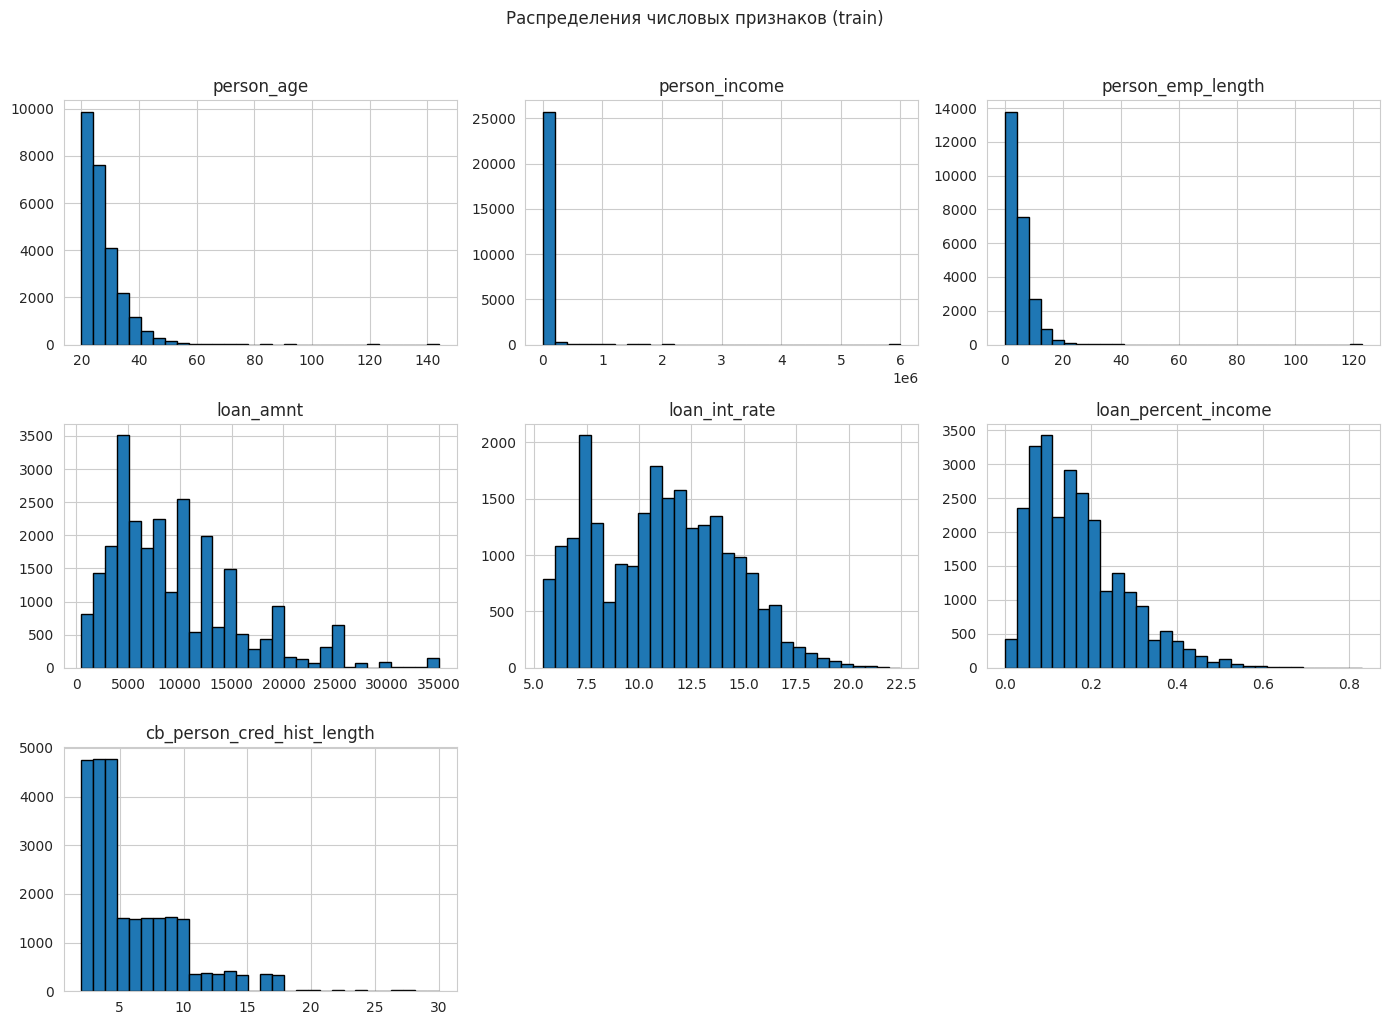

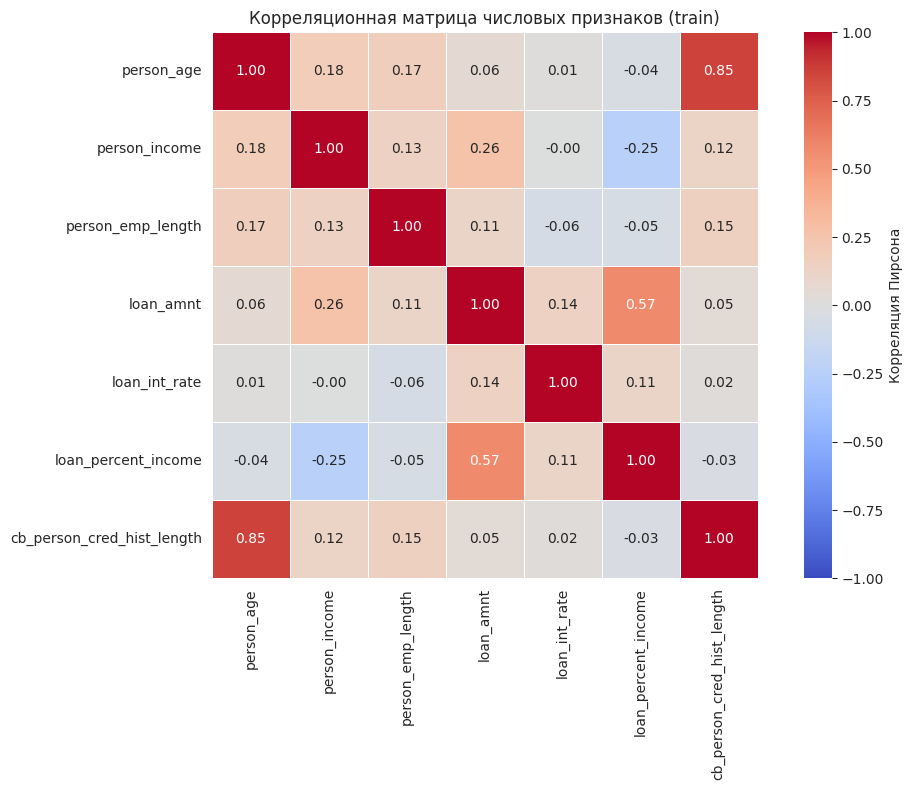

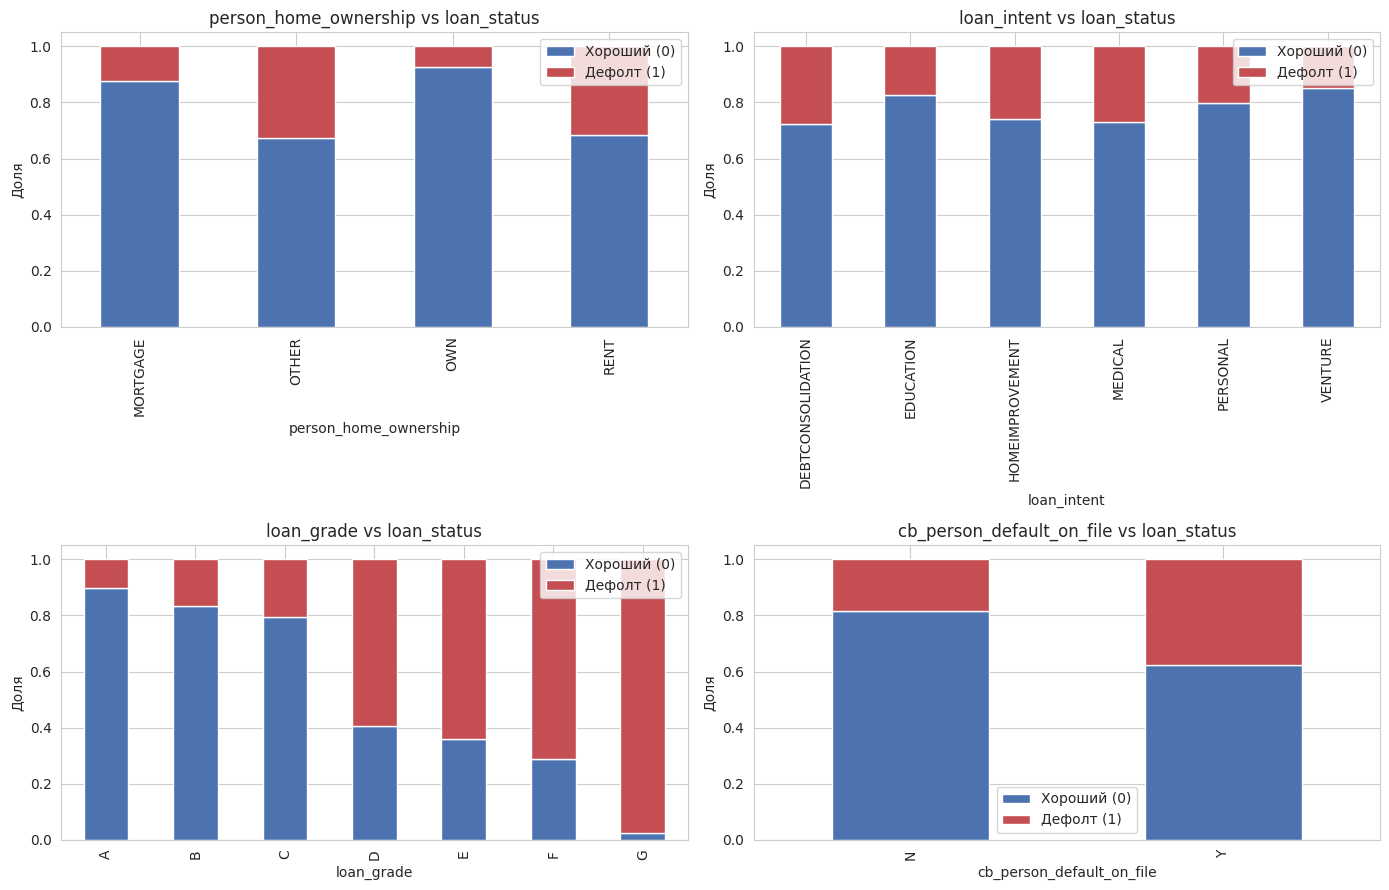

In [63]:
# --- 3.1. Числовые признаки: describe ---
numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
print("Числовые:", numeric_cols)
print("Категориальные:", categorical_cols)

print("\nОписательные статистики (train):")
display(X_train[numeric_cols].describe().T)

# --- 3.2. Распределение целевой переменной ---
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
y_train.value_counts().plot(kind='bar', ax=ax[0], color=['#4c72b0', '#c44e52'])
ax[0].set_title('Целевая переменная (train)')
ax[0].set_xticklabels(['Хороший (0)', 'Дефолт (1)'], rotation=0)
y_train.value_counts(normalize=True).plot(kind='pie', ax=ax[1], autopct='%1.1f%%',
                                          labels=['Хороший (0)', 'Дефолт (1)'])
ax[1].set_ylabel('')
ax[1].set_title('Доли классов')
plt.tight_layout(); plt.show()

# --- 3.3. Гистограммы числовых признаков ---
X_train[numeric_cols].hist(figsize=(14, 10), bins=30, edgecolor='black')
plt.suptitle('Распределения числовых признаков (train)', y=1.02)
plt.tight_layout(); plt.show()

# --- 3.4. Корреляционная матрица (только числовые) ---
plt.figure(figsize=(11, 8))
corr = X_train[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
            cbar_kws={'label': 'Корреляция Пирсона'})
plt.title('Корреляционная матрица числовых признаков (train)')
plt.tight_layout(); plt.show()

# --- 3.5. Категориальные признаки: связь с целевой ---
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flat, categorical_cols[:4]):
    pd.crosstab(X_train[col], y_train, normalize='index').plot(
        kind='bar', stacked=True, ax=ax, color=['#4c72b0', '#c44e52'])
    ax.set_title(f'{col} vs loan_status')
    ax.set_ylabel('Доля'); ax.legend(['Хороший (0)', 'Дефолт (1)'])
plt.tight_layout(); plt.show()

#Шаг 4. Обработка выбросов

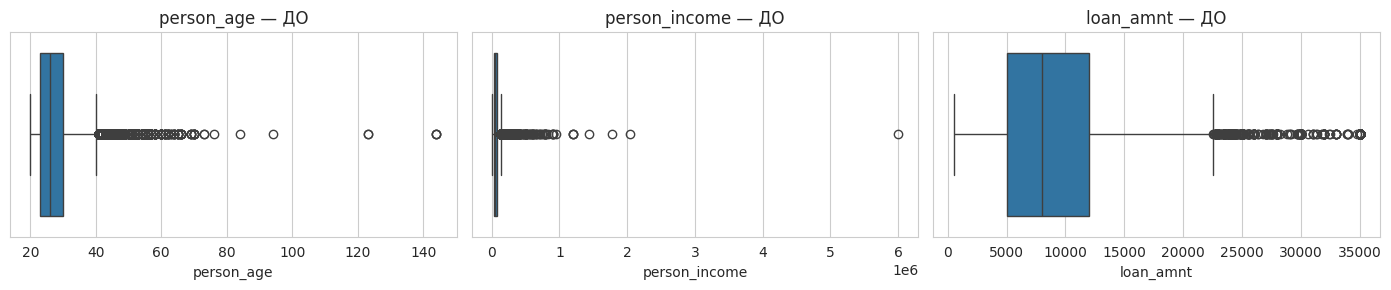

person_age: [12.5, 40.5]
person_income: [-22391.9, 139835.1]
person_emp_length: [-5.5, 14.5]
loan_amnt: [-5500.0, 22500.0]


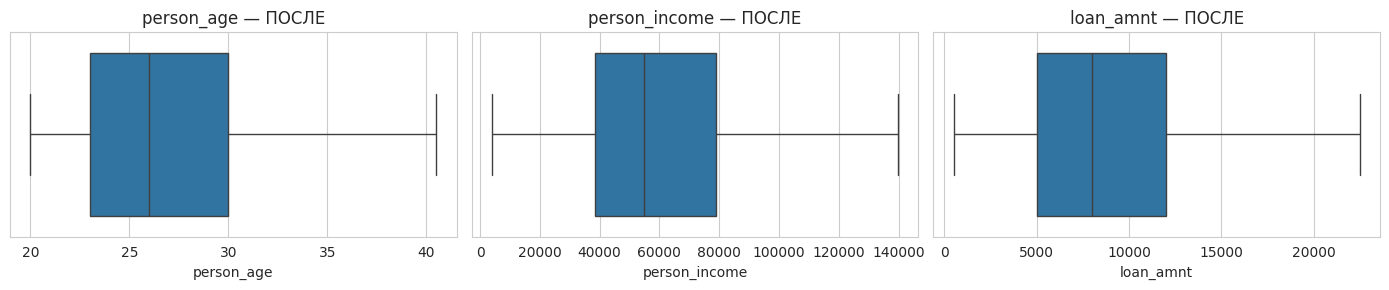

In [64]:
def cap_outliers_iqr(train, test, cols):
    """Цензурирование по IQR: границы считаем по train, применяем к обоим."""
    tr, te = train.copy(), test.copy()
    bounds = {}
    for col in cols:
        q1, q3 = tr[col].quantile(0.25), tr[col].quantile(0.75)
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        bounds[col] = (lo, hi)
        tr[col] = tr[col].clip(lo, hi)
        te[col] = te[col].clip(lo, hi)
    return tr, te, bounds

# Боксплоты ДО — наглядно видно выбросы
plt.figure(figsize=(14, 3))
for i, col in enumerate(['person_age', 'person_income', 'loan_amnt'], 1):
    plt.subplot(1, 3, i); sns.boxplot(x=X_train[col]); plt.title(f'{col} — ДО')
plt.tight_layout(); plt.show()

X_train, X_test, bounds = cap_outliers_iqr(
    X_train, X_test,
    cols=['person_age', 'person_income', 'person_emp_length', 'loan_amnt']
)
for col, (lo, hi) in bounds.items():
    print(f"{col}: [{lo:.1f}, {hi:.1f}]")

# Боксплоты ПОСЛЕ
plt.figure(figsize=(14, 3))
for i, col in enumerate(['person_age', 'person_income', 'loan_amnt'], 1):
    plt.subplot(1, 3, i); sns.boxplot(x=X_train[col]); plt.title(f'{col} — ПОСЛЕ')
plt.tight_layout(); plt.show()

# Шаг 5. Обработка пропущенных значений

In [65]:
miss_train = X_train.isnull().sum()
miss_test  = X_test.isnull().sum()
print("Пропуски в train:\n", miss_train[miss_train > 0])
print("Пропуски в test:\n",  miss_test[miss_test > 0])

# Медиана — считается на train, применяется к обоим наборам
for col in X_train.columns:
    if X_train[col].isnull().any():
        if X_train[col].dtype in ['float64', 'int64']:
            fill = X_train[col].median()
            X_train[col] = X_train[col].fillna(fill)
            X_test[col]  = X_test[col].fillna(fill)
            print(f"  {col}: заполнено медианой = {fill:.2f}")
        else:
            fill = X_train[col].mode()[0]
            X_train[col] = X_train[col].fillna(fill)
            X_test[col]  = X_test[col].fillna(fill)
            print(f"  {col}: заполнено модой = {fill}")

assert X_train.isnull().sum().sum() == 0 and X_test.isnull().sum().sum() == 0
print("\nПропусков больше нет.")

Пропуски в train:
 person_emp_length     738
loan_int_rate        2501
dtype: int64
Пропуски в test:
 person_emp_length    157
loan_int_rate        615
dtype: int64
  person_emp_length: заполнено медианой = 4.00
  loan_int_rate: заполнено медианой = 10.99

Пропусков больше нет.


#Шаги 6 и 7. Категориальные признаки + нормализация

In [66]:
# Поскольку OneHotEncoder выдаёт 0/1 (уже "числовые" значения), его ставим рядом со StandardScaler
# в ColumnTransformer — так масштаб корректно применяется только к числовым признакам.
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),                    # шаг 7: нормализация
        ('cat', OneHotEncoder(handle_unknown='ignore',
                              sparse_output=False), categorical_cols)  # шаг 6: кодирование
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)     # fit — только на train!
X_test_processed  = preprocessor.transform(X_test)          # transform — на test

print("Размер после препроцессинга:")
print(f"  train: {X_train_processed.shape}")
print(f"  test:  {X_test_processed.shape}")

# Посмотреть имена получившихся признаков
feature_names = preprocessor.get_feature_names_out()
print(f"\nВсего признаков: {len(feature_names)}")
print("Примеры:", list(feature_names[:8]))

Размер после препроцессинга:
  train: (26064, 26)
  test:  (6517, 26)

Всего признаков: 26
Примеры: ['num__person_age', 'num__person_income', 'num__person_emp_length', 'num__loan_amnt', 'num__loan_int_rate', 'num__loan_percent_income', 'num__cb_person_cred_hist_length', 'cat__person_home_ownership_MORTGAGE']


#Шаг 8. Классификатор K-ближайших соседей
Почему KNN: простой и наглядный, отлично демонстрирует важность нормализации; не требует «обучения коэффициентов» — то есть по построению не боится мультиколлинеарности (шаг 12); хорошо работает как baseline для табличных данных. В качестве альтернатив (шаг 10) сравним с логистической регрессией и случайным лесом.

In [67]:
# Базовый запуск для оценки
knn_base = KNeighborsClassifier(n_neighbors=5)
knn_base.fit(X_train_processed, y_train)
y_train_pred = knn_base.predict(X_train_processed)
y_test_pred  = knn_base.predict(X_test_processed)

train_err = 1 - accuracy_score(y_train, y_train_pred)
test_err  = 1 - accuracy_score(y_test,  y_test_pred)
print(f"Ошибка на train: {train_err:.4f}")
print(f"Ошибка на test:  {test_err:.4f}")

Ошибка на train: 0.0821
Ошибка на test:  0.1123


#Шаг 9. Ошибки, матрицы рассогласования, подбор k

=== KNN (k=5) ===


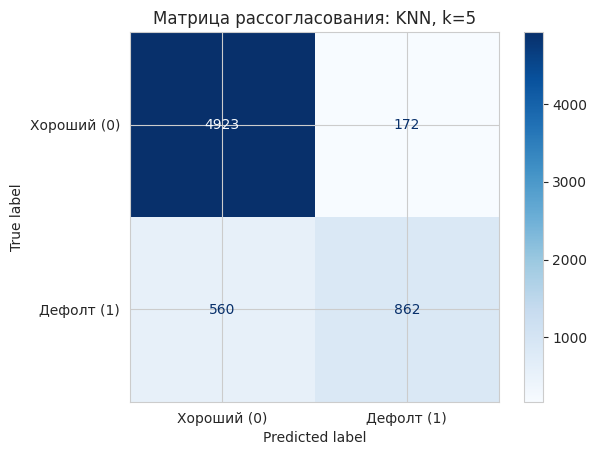

              precision    recall  f1-score   support

 Хороший (0)       0.90      0.97      0.93      5095
  Дефолт (1)       0.83      0.61      0.70      1422

    accuracy                           0.89      6517
   macro avg       0.87      0.79      0.82      6517
weighted avg       0.88      0.89      0.88      6517


Лучшее k = 11
Лучший F1 (CV, среднее) = 0.7095


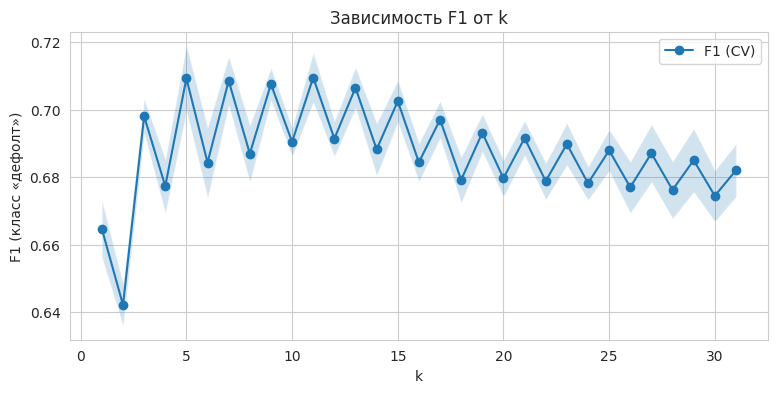


=== KNN (k=11) на тесте ===
Ошибка на train: 0.0934
Ошибка на test:  0.1086


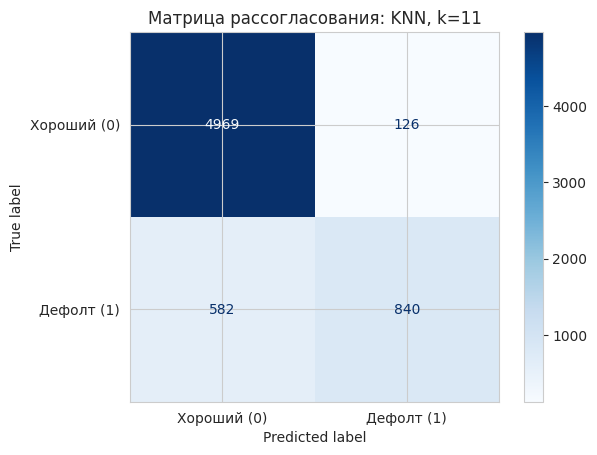

              precision    recall  f1-score   support

 Хороший (0)       0.90      0.98      0.93      5095
  Дефолт (1)       0.87      0.59      0.70      1422

    accuracy                           0.89      6517
   macro avg       0.88      0.78      0.82      6517
weighted avg       0.89      0.89      0.88      6517



In [68]:
# --- 9.1. Матрица рассогласования для базовой модели ---
print("=== KNN (k=5) ===")
cm = confusion_matrix(y_test, y_test_pred)
ConfusionMatrixDisplay(cm, display_labels=['Хороший (0)', 'Дефолт (1)']).plot(cmap='Blues')
plt.title('Матрица рассогласования: KNN, k=5')
plt.show()
print(classification_report(y_test, y_test_pred, target_names=['Хороший (0)', 'Дефолт (1)']))

# --- 9.2. Подбор оптимального k через 5-кратную CV по F1-мере ---
pipe = Pipeline([
    ('prep', preprocessor),
    ('clf',  KNeighborsClassifier())
])

param_grid = {'clf__n_neighbors': list(range(1, 32))}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='f1', n_jobs=-1)
grid.fit(X_train, y_train)   # передаём СЫРОЙ X_train — пайплайн сделает препроцессинг внутри CV

print(f"\nЛучшее k = {grid.best_params_['clf__n_neighbors']}")
print(f"Лучший F1 (CV, среднее) = {grid.best_score_:.4f}")

# --- 9.3. Кривая F1(CV) vs k ---
cv_results = pd.DataFrame(grid.cv_results_)
plt.figure(figsize=(9, 4))
plt.plot(cv_results['param_clf__n_neighbors'], cv_results['mean_test_score'],
         marker='o', label='F1 (CV)')
plt.fill_between(cv_results['param_clf__n_neighbors'],
                 cv_results['mean_test_score'] - cv_results['std_test_score'],
                 cv_results['mean_test_score'] + cv_results['std_test_score'],
                 alpha=0.2)
plt.xlabel('k'); plt.ylabel('F1 (класс «дефолт»)')
plt.title('Зависимость F1 от k'); plt.legend(); plt.grid(True); plt.show()

# --- 9.4. Финальная оценка модели с лучшим k на тесте ---
best_knn = grid.best_estimator_
y_test_pred_best = best_knn.predict(X_test)
y_train_pred_best = best_knn.predict(X_train)

print(f"\n=== KNN (k={grid.best_params_['clf__n_neighbors']}) на тесте ===")
print(f"Ошибка на train: {1 - accuracy_score(y_train, y_train_pred_best):.4f}")
print(f"Ошибка на test:  {1 - accuracy_score(y_test,  y_test_pred_best):.4f}")
cm_best = confusion_matrix(y_test, y_test_pred_best)
ConfusionMatrixDisplay(cm_best, display_labels=['Хороший (0)', 'Дефолт (1)']).plot(cmap='Blues')
plt.title(f'Матрица рассогласования: KNN, k={grid.best_params_["clf__n_neighbors"]}')
plt.show()
print(classification_report(y_test, y_test_pred_best, target_names=['Хороший (0)', 'Дефолт (1)']))

#Шаг 10. Сравнение с другими классификаторами

In [69]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42,
                                              class_weight='balanced'),
    'Random Forest':       RandomForestClassifier(n_estimators=300, random_state=42,
                                                  class_weight='balanced', n_jobs=-1),
    'KNN (best k)':        KNeighborsClassifier(n_neighbors=grid.best_params_['clf__n_neighbors'])
}

results = {}
for name, model in models.items():
    p = Pipeline([('prep', preprocessor), ('clf', model)])
    p.fit(X_train, y_train)
    pred = p.predict(X_test)
    results[name] = {
        'Accuracy':        accuracy_score(y_test, pred),
        'Precision (1)':   precision_score(y_test, pred, pos_label=1),
        'Recall (1)':      recall_score(y_test, pred, pos_label=1),
        'F1 (1)':          f1_score(y_test, pred, pos_label=1),
    }
    print(f"\n--- {name} ---")
    print(classification_report(y_test, pred, target_names=['Хороший (0)', 'Дефолт (1)']))

summary = pd.DataFrame(results).T.round(4)
print("\n=== Сводная таблица (тест) ===")
display(summary)


--- Logistic Regression ---
              precision    recall  f1-score   support

 Хороший (0)       0.93      0.82      0.87      5095
  Дефолт (1)       0.55      0.78      0.65      1422

    accuracy                           0.81      6517
   macro avg       0.74      0.80      0.76      6517
weighted avg       0.85      0.81      0.82      6517


--- Random Forest ---
              precision    recall  f1-score   support

 Хороший (0)       0.93      1.00      0.96      5095
  Дефолт (1)       0.98      0.71      0.82      1422

    accuracy                           0.93      6517
   macro avg       0.95      0.85      0.89      6517
weighted avg       0.94      0.93      0.93      6517


--- KNN (best k) ---
              precision    recall  f1-score   support

 Хороший (0)       0.90      0.98      0.93      5095
  Дефолт (1)       0.87      0.59      0.70      1422

    accuracy                           0.89      6517
   macro avg       0.88      0.78      0.82      6517


,Accuracy,Precision (1),Recall (1),F1 (1)
Logistic Regression,0.815,0.553,0.783,0.648
Random Forest,0.934,0.977,0.714,0.825
KNN (best k),0.891,0.870,0.591,0.704


#Шаг 11. Борьба с несбалансированностью (SMOTE)

In [70]:
# Важно: SMOTE применяем ТОЛЬКО к train (после препроцессинга) — иначе утечка.
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train_processed, y_train)

print("До SMOTE:", np.bincount(y_train))
print("После SMOTE:", np.bincount(y_train_sm))

knn_sm = KNeighborsClassifier(n_neighbors=grid.best_params_['clf__n_neighbors'])
knn_sm.fit(X_train_sm, y_train_sm)
y_pred_sm = knn_sm.predict(X_test_processed)

print("\n=== KNN после SMOTE (тест) ===")
print(classification_report(y_test, y_pred_sm, target_names=['Хороший (0)', 'Дефолт (1)']))

# Сравнение с моделью без SMOTE
print("\nСравнение (только по классу «дефолт»):")
print(f"{'':20s} {'F1':>8s} {'Recall':>8s}")
print(f"{'Без SMOTE':20s} {f1_score(y_test, y_test_pred_best, pos_label=1):8.4f} "
      f"{recall_score(y_test, y_test_pred_best, pos_label=1):8.4f}")
print(f"{'Со SMOTE':20s} {f1_score(y_test, y_pred_sm, pos_label=1):8.4f} "
      f"{recall_score(y_test, y_pred_sm, pos_label=1):8.4f}")

До SMOTE: [20378  5686]
После SMOTE: [20378 20378]

=== KNN после SMOTE (тест) ===
              precision    recall  f1-score   support

 Хороший (0)       0.93      0.83      0.88      5095
  Дефолт (1)       0.56      0.78      0.65      1422

    accuracy                           0.82      6517
   macro avg       0.74      0.80      0.76      6517
weighted avg       0.85      0.82      0.83      6517


Сравнение (только по классу «дефолт»):
                           F1   Recall
Без SMOTE              0.7035   0.5907
Со SMOTE               0.6491   0.7799


# Шаг 12. Исключение коррелированных переменных

In [71]:
# Считаем корреляции только на исходных числовых признаках train
corr_abs = X_train[numeric_cols].corr().abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))

threshold = 0.85
pairs = upper.stack().loc[lambda s: s > threshold].sort_values(ascending=False)
print(f"Пары с |r| > {threshold}:")
print(pairs.to_string() if len(pairs) else "  (нет)")

to_drop = [c for c in upper.columns if any(upper[c] > threshold)]
print(f"\nПризнаки к удалению: {to_drop}")

# Модель ПОСЛЕ удаления
if to_drop:
    numeric_reduced = [c for c in numeric_cols if c not in to_drop]
    prep_red = ColumnTransformer([
        ('num', StandardScaler(), numeric_reduced),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ])
    X_train_red = prep_red.fit_transform(X_train)
    X_test_red  = prep_red.transform(X_test)

    knn_red = KNeighborsClassifier(n_neighbors=grid.best_params_['clf__n_neighbors'])
    knn_red.fit(X_train_red, y_train)
    y_pred_red = knn_red.predict(X_test_red)

    comparison = pd.DataFrame({
        'Модель':          ['KNN (все признаки)', 'KNN (без коррелированных)'],
        'Accuracy':        [accuracy_score(y_test, y_test_pred_best),
                            accuracy_score(y_test, y_pred_red)],
        'F1 (дефолт)':     [f1_score(y_test, y_test_pred_best, pos_label=1),
                            f1_score(y_test, y_pred_red, pos_label=1)],
        'Recall (дефолт)': [recall_score(y_test, y_test_pred_best, pos_label=1),
                            recall_score(y_test, y_pred_red, pos_label=1)],
    }).set_index('Модель')
    display(comparison.round(4))
else:
    print("Порог не превышен — удалять нечего.")

Пары с |r| > 0.85:
person_age  cb_person_cred_hist_length   0.858

Признаки к удалению: ['cb_person_cred_hist_length']


,Accuracy,F1 (дефолт),Recall (дефолт)
Модель,,,
KNN (все признаки),0.891,0.704,0.591
KNN (без коррелированных),0.897,0.718,0.603
